In [1]:
# ============================== Setup ==============================
import os, re, glob, base64, hashlib, binascii, warnings
from decimal import Decimal, ROUND_HALF_UP
from urllib.parse import urlsplit, parse_qsl, unquote
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib import font_manager as fm
from IPython.display import display

DATA_DIR = "./dataset"              # output folder of export_adclickid_data.py
TRACKERDB_CSV = "./trackerdb_domains.csv"     # Ghostery TrackerDB: domain, organization_id
FIG_DIR, TAB_DIR = "./figures", "./tables"

COUNTRY_ORDER = ["AU", "BR", "DE", "JP", "US", "ZA"]
COUNTRY_LABEL = {"AU": "Australia", "BR": "Brazil", "DE": "Germany", "JP": "Japan", "US": "United States", "ZA": "South Africa"}
CASE_ORDER = ["no-interaction", "accept-all", "reject-all"]
CASE_LABEL = {"no-interaction": "No interaction", "accept-all": "Accept all", "reject-all": "Reject all"}
PLATFORM_ORDER = ["FB", "TT", "TW", "GG", "MS", "YH"]
PLATFORM_LABEL = {"FB": "Meta Ads", "TT": "TikTok Ads", "TW": "X Ads", "GG": "Google Ads", "MS": "Microsoft Advertising", "YH": "Yahoo! JAPAN Ads"}
CLICKID_NAME = {"FB": "fbclid", "TT": "ttclid", "TW": "twclid", "GG": "gclid", "MS": "msclkid", "YH": "yclid"}
PLATFORM_ENTITY = {"FB": "meta", "GG": "google", "MS": "microsoft", "TW": "twitter", "TT": "tiktok", "YH": "yahoo"}
LOGIN_PLATFORMS = ["FB", "TT", "TW"]
EXCLUDE_PLATFORM_COUNTRY = {"DE": ["YH"]}      # Yahoo! JAPAN Ads has no German VP
MIN_N = 8
ALIAS_MIN_LEN = 10

FONT_FAMILY = "Linux Libertine O"
FONT_FALLBACKS = ["Libertinus Serif", "Linux Libertine", "Linux Libertine G", "DejaVu Serif"]
FONT_FILES = []
COL_W, FULL_W = 3.33, 7.0
STYLE = dict(font_size=8, grid=True, grid_axis="y", grid_ls=":", grid_lw=0.6, grid_alpha=0.6, legend=True, legend_loc="best", legend_ncol=1,
             legend_frame=False, legend_size=7, legend_bbox=None, annotate=False, annot_fmt="{:.1%}", annot_size=6, annot_min=0.06,
             bar_width=0.8, edgecolor="none", percent=True, ylim=None, xlim=None, xlabel=None, ylabel=None, xticklabels=None,
             yticklabels=None, xtick_rotation=0, colors=None, cmap="Blues", figsize=(COL_W, 2.2))

PLATFORM_COLORS = {"FB": "#3b5998", "TT": "#25b8c4", "TW": "#444444", "GG": "#ea4335", "MS": "#7fba00", "YH": "#ff0033", "All": "#000000"}
COMPLIANCE_COLORS = {"Compliant": "#1b9e77", "Non-compliant": "#d95f02", "No AdClick-ID storage": "#d9d9d9"}
STATE_COLORS = {"No banner": "#9e9e9e", "Banner · NI": "#4c72b0", "Banner · A": "#55a868", "Banner · R": "#c44e52"}
ENC_GROUP = {"exact": "Plaintext", "embedded": "Plaintext", "urlenc": "URL-encoded", "b64": "Base64", "b64url": "Base64",
             "md5": "Hashed", "sha1": "Hashed", "sha256": "Hashed"}
CHANNEL_LABEL = {"uri": "URL", "body": "Payload", "referer": "Referer", "cookie": "Cookie header", "set_cookie": "Set-Cookie",
                 "other_header": "Other header", "resp": "Response"}
STATE_TITLE = {"No banner": "No banner, no interaction", "Banner · NI": "Banner, no interaction",
               "Banner · A": "Banner, accept all", "Banner · R": "Banner, reject all"}

FIG = {
    "fig01_banner": dict(figsize=(COL_W, 2.0), cmap="Blues", annotate=True, annot_fmt="pnum", annot_size=7, xtick_rotation=30),
    "fig02_compliance_platform": dict(figsize=(COL_W * 1.3, 1.9), colors=COMPLIANCE_COLORS, xlim=(0, 1), xlabel="Advertiser–VP pairs with a banner",
                                      legend_loc="lower center", legend_bbox=(0.45, 1.0), legend_ncol=3, grid_axis="x", annotate=True,
                                      annot_fmt="{:.1%}", annot_size=5.5, annot_min=0.07),
    "fig05_storage": dict(figsize=(FULL_W, 2.3), cmap="Oranges", annotate=True, annot_fmt="pnum", annot_size=7, xtick_rotation=40,
                          titles={"Banner · NI": "Banner · No interaction", "Banner · A": "Banner · Accept all", "Banner · R": "Banner · Reject all"}),
    "fig08b_top_entries_by_case": dict(figsize=(COL_W * 0.65, 5.4), cmap="YlOrRd", annotate=True, annot_fmt="pnum", annot_size=7,
                                       top_per_platform=5, max_label=40, xtick_rotation=0),
    "fig07_lifetime": dict(figsize=(COL_W, 3.8), colors=PLATFORM_COLORS, linestyles={"YH": (0, (4, 1.5))}, color_override={"YH": "#8E44AD"},
                           lw=1.1, min_days=1 / 24, xticks=[1, 7, 30, 90, 365], xlabel="Lifetime of AdClick-ID cookie (days, log scale)",
                           ylabel="Pairs (CDF)", legend_ncol=3, grid_axis="both"),
    "fig10_crossplatform": dict(figsize=(FULL_W, 3.9)),
    "fig12b_3p_ccdf": dict(figsize=(COL_W, 2.0), lw=1.1, xlabel="Third-party tracking domains receiving the AdClick-ID", ylabel="Pairs (CCDF)",
                           legend=True, legend_loc="upper right", legend_ncol=1, grid_axis="both",
                           titles={"Banner · NI": "Banner · No Interaction", "Banner · A": "Banner · Accept all", "Banner · R": "Banner · Reject all"}),
    "figA_channels": dict(figsize=(FULL_W * 0.75, 3.2), cmap="Purples", annotate=True, annot_fmt="pnum", annot_size=7, xtick_rotation=40),
}

In [2]:
# ============================== Helpers ==============================
warnings.filterwarnings("ignore")
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(TAB_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)


def PCT(x, d=1):
    """Percentage, rounded half-up to one decimal: PCT(0.3545) = '35.5%'."""
    try:
        if x is None or pd.isna(x):
            return "n/a"
    except (TypeError, ValueError):
        pass
    q = Decimal(repr(round(float(x) * 100, 9))).quantize(Decimal(1).scaleb(-d), rounding=ROUND_HALF_UP)
    return f"{q}%"


def PNUM(x, d=1):
    s = PCT(x, d)
    return s[:-1] if s.endswith("%") else s


def fmt_annot(s, v):
    if s["annot_fmt"] == "pnum":
        return PNUM(v)
    return PCT(v) if "%" in s["annot_fmt"] else str.format(s["annot_fmt"], v)


def kn(k, n):
    k, n = int(k), int(n)
    return f"{k:,} / {n:,} ({PCT(k / n)})" if n else f"{k:,} / 0"


def show(label, k, n=None):
    """Print one number of the paper: 'label: k / n (x%)', or 'label: k' without a denominator."""
    print(f"{label}: {kn(k, n)}" if n is not None else f"{label}: {k:,}" if isinstance(k, (int, np.integer)) else f"{label}: {k}")


def show_range(label, d):
    """d = {name: (k, n)} -> 'label: from x% (name) to y% (name)'."""
    d = {k: v for k, v in d.items() if v[1]}
    r = {k: v[0] / v[1] for k, v in d.items()}
    lo, hi = min(r, key=r.get), max(r, key=r.get)
    print(f"{label}: from {kn(*d[lo])} ({lo}) to {kn(*d[hi])} ({hi})")


def setup_fonts():
    for f in FONT_FILES:
        try:
            fm.fontManager.addfont(f)
        except Exception as e:
            print("Font file not loaded:", f, e)
    avail = {f.name for f in fm.fontManager.ttflist}
    fam = next((f for f in [FONT_FAMILY] + FONT_FALLBACKS if f in avail), "serif")
    mpl.rcParams.update({"font.family": "serif", "font.serif": [fam] + FONT_FALLBACKS, "font.size": STYLE["font_size"],
                         "axes.titlesize": STYLE["font_size"], "axes.labelsize": STYLE["font_size"], "xtick.labelsize": STYLE["font_size"] - 1,
                         "ytick.labelsize": STYLE["font_size"] - 1, "legend.fontsize": STYLE["legend_size"], "pdf.fonttype": 42, "ps.fonttype": 42,
                         "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.6, "xtick.major.width": 0.6,
                         "ytick.major.width": 0.6, "savefig.bbox": "tight", "savefig.pad_inches": 0.02, "figure.dpi": 130})
    print("Font:", fam)


setup_fonts()


def S(name, **defaults):
    s = dict(STYLE); s.update(defaults)
    s.update({k: v for k, v in FIG.get(name, {}).items() if v is not None})
    return s


def style_ax(ax, s, percent_axis="y"):
    if s.get("grid"):
        ax.grid(True, axis=s.get("grid_axis", "y"), ls=s["grid_ls"], lw=s["grid_lw"], alpha=s["grid_alpha"]); ax.set_axisbelow(True)
    else:
        ax.grid(False)
    if s.get("ylim") is not None: ax.set_ylim(*s["ylim"])
    if s.get("xlim") is not None: ax.set_xlim(*s["xlim"])
    if s.get("xlabel") is not None: ax.set_xlabel(s["xlabel"])
    if s.get("ylabel") is not None: ax.set_ylabel(s["ylabel"])
    if s.get("percent") and percent_axis:
        (ax.yaxis if percent_axis == "y" else ax.xaxis).set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
    if s.get("xtick_rotation"):
        plt.setp(ax.get_xticklabels(), rotation=s["xtick_rotation"], ha="right")


def legend(ax, s, **kw):
    if not s.get("legend"):
        return
    if s.get("legend_bbox") is not None and "bbox_to_anchor" not in kw:
        kw["bbox_to_anchor"] = s["legend_bbox"]
    ax.legend(loc=s["legend_loc"], ncol=s["legend_ncol"], frameon=s["legend_frame"], fontsize=s["legend_size"], **kw)


def save_fig(fig, name):
    path = os.path.join(FIG_DIR, name + ".pdf")
    fig.savefig(path); plt.show(); plt.close(fig)
    print("->", path)


def save_table(df, name):
    path = os.path.join(TAB_DIR, name + ".csv")
    df.to_csv(path); display(df)
    print("->", path)


def to_bool(s):
    if s.dtype == bool:
        return s
    return s.astype(str).str.strip().str.lower().isin(["true", "t", "1", "yes"])


NAME_ID_RE = re.compile(r"([_.-])(?:[0-9a-f]{8,}|(?=[0-9A-Za-z]*[0-9])[0-9A-Za-z]{6,})$")
norm_name = lambda n: NAME_ID_RE.sub(r"\1*", str(n))          # AMP_MKTG_f70dc3ca69 -> AMP_MKTG_*


def heat(ax, piv, s, vmin=0, vmax=1):
    ax.imshow(piv.values.astype(float), cmap=s["cmap"], vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(piv.shape[1])); ax.set_yticks(range(piv.shape[0]))
    ax.set_xticklabels(s["xticklabels"] or list(piv.columns)); ax.set_yticklabels(s["yticklabels"] or list(piv.index))
    ax.tick_params(length=0); ax.grid(False)
    for sp in ax.spines.values():
        sp.set_visible(False)
    if s["annotate"]:
        for i in range(piv.shape[0]):
            for j in range(piv.shape[1]):
                v = piv.values[i, j]
                if pd.notna(v):
                    ax.text(j, i, fmt_annot(s, v), ha="center", va="center", fontsize=s["annot_size"],
                            color="white" if (v - vmin) / (vmax - vmin + 1e-9) > .6 else "black")
    if s.get("xtick_rotation"):
        plt.setp(ax.get_xticklabels(), rotation=s["xtick_rotation"], ha="right")


def stacked(ax, t, colors, s, labels=None):
    """Horizontal stacked bars; t: rows = bars, columns = parts (sum = 1)."""
    base = np.zeros(len(t)); pos = np.arange(len(t))
    for c in t.columns:
        v = t[c].values
        ax.barh(pos, v, left=base, color=colors.get(c), label=c, height=s["bar_width"], edgecolor=s["edgecolor"])
        if s["annotate"]:
            for i, (b0, vv) in enumerate(zip(base, v)):
                if vv >= s["annot_min"]:
                    ax.text(b0 + vv / 2, i, fmt_annot(s, vv), ha="center", va="center", fontsize=s["annot_size"])
        base += v
    ax.set_yticks(pos); ax.set_yticklabels(labels or list(t.index))

Font: DejaVu Serif


In [3]:
# ============================== Data ==============================
KINDS = ["sites_summary", "clickid_flags", "clickid_occ_storage", "clickid_occ_requests"]
FILE_RE = re.compile(r"^(?P<country>[A-Z]{2})_(?P<case>no-interaction|accept-all|reject-all)_(?P<kind>[a-z_]+)\.csv$")


def drop_excluded(df):
    if len(df) and "platform" in df:
        drop = pd.Series(False, index=df.index)
        for c, plats in EXCLUDE_PLATFORM_COUNTRY.items():
            drop |= (df["country"] == c) & df["platform"].isin(plats)
        df = df[~drop].reset_index(drop=True)
    return df


def read_kind(kind):
    frames = []
    for p in sorted(glob.glob(os.path.join(DATA_DIR, "*.csv"))):
        m = FILE_RE.match(os.path.basename(p))
        if not m or m["kind"] != kind:
            continue
        kw = dict(keep_default_na=False, na_values=[""]) if kind == "clickid_occ_storage" else {}   # keep the string "None"
        try:
            df = pd.read_csv(p, low_memory=False, **kw)
        except pd.errors.EmptyDataError:
            continue
        df["country"], df["case"] = m["country"], m["case"]
        frames.append(df)
    out = drop_excluded(pd.concat(frames, ignore_index=True) if frames else pd.DataFrame())
    print(f"{kind:<26} {len(frames):>3} files {len(out):>10,} rows")
    return out


SITES, FL, OST, ORQ = (read_kind(k) for k in KINDS)
if "is_navigation" not in ORQ:
    ORQ["is_navigation"] = False
FL["stored"] = to_bool(FL["stored"])
OST["is_after"] = to_bool(OST["is_after"])
for c in ["is_tracker", "is_navigation", "is_after"]:
    ORQ[c] = to_bool(ORQ[c])
OST["is_first_party"] = OST["is_first_party"].map(lambda x: np.nan if pd.isna(x) or str(x).strip() == "" else str(x).strip().lower() in ("true", "1", "t"))
OST["lifetime_days"] = pd.to_numeric(OST["lifetime_days"], errors="coerce")
COUNTRIES = [c for c in COUNTRY_ORDER if c in set(SITES["country"])]
PLATFORMS = [p for p in PLATFORM_ORDER if p in set(SITES["platform"])]
CL = [COUNTRY_LABEL[c] for c in COUNTRIES]
PL = lambda p: PLATFORM_LABEL.get(p, p)
ROWS = PLATFORMS + ["All"]

# ---- organization of a domain: Ghostery TrackerDB ----
TDB = pd.read_csv(TRACKERDB_CSV, dtype=str)
TDB_HOST = dict(zip(TDB.domain.str.lower(), TDB.organization_id))
_e1 = lambda d: ".".join(d.split(".")[-3:]) if re.search(r"\.(co|com|ne|or|ac|go)\.[a-z]{2}$", d) else ".".join(d.split(".")[-2:])
_ed = TDB.assign(e1=TDB.domain.str.lower().map(_e1)).groupby("e1").organization_id.agg(lambda s: set(s))
TDB_ETLD1 = {e: next(iter(o)) for e, o in _ed.items() if len(o) == 1}
TDB_ORG2COMPANY = {"google": "google", "facebook": "meta", "microsoft": "microsoft", "bytedance_inc": "tiktok", "twitter": "twitter",
                   "yahoo_japan": "yahoo"}


def tdb_org(host, etld1=None):
    h = str(host or "").lower().strip(".")
    parts = h.split(".")
    for i in range(len(parts) - 1):
        o = TDB_HOST.get(".".join(parts[i:]))
        if o:
            return o, "host"
    e = str(etld1 or _e1(h)).lower()
    return (TDB_ETLD1[e], "etld1") if e in TDB_ETLD1 else (None, "none")


def company_of(host, etld1=None):
    return TDB_ORG2COMPANY.get(tdb_org(host, etld1)[0], "other")


_GCC = re.compile(r"^google\.(?:com?\.)?[a-z]{2,3}$")

# ---- advertiser = eTLD+1 of the landing page (mode over visits of the AdURL) ----
KEY = ["country", "case", "platform", "adv"]
KEY3 = ["country", "platform", "adv"]
ADV_OF = SITES.dropna(subset=["reached_etld1"]).groupby(["platform", "id_csv"])["reached_etld1"].agg(lambda s: s.mode().iat[0]).to_dict()
for df in (SITES, FL, OST, ORQ):
    if len(df):
        df["adv"] = [ADV_OF.get((p, i), f"id{i}") for p, i in zip(df["platform"], df["id_csv"])]

VIS = SITES[["vid", "country", "case", "platform", "id_csv", "adv", "run_no"]].copy()
VIS["has_cid"] = VIS["vid"].isin(set(FL["vid"]))
VIS = VIS.merge(FL[["vid", "stored"]], on="vid", how="left")
VIS["stored"] = VIS["stored"].fillna(False).astype(bool)

# tracking requests, without the navigation chain of the AdURL
REQ = ORQ[ORQ.is_tracker & ~ORQ.is_navigation].copy()
REQ["ch"] = REQ["channel"].replace({"resp_body": "resp", "resp_header": "resp", "location": "resp"})

# ---- visits -> advertiser–VP pair per case: majority over runs ----
_THR = lambda f: f >= .5
v_ = VIS[VIS.has_cid]
ADV = v_.groupby(KEY)["stored"].agg(lambda s: float(s.mean() >= .5)).astype(int).reset_index()
VKEY = VIS.set_index("vid")[KEY]
NVIS = v_.groupby(KEY).size()


def occ_to_adv(df, label):
    """Occurrence rows (with 'vid') -> (pair, case, label) kept by majority over the runs of the case."""
    d = df[["vid", label]].dropna().drop_duplicates().join(VKEY, on="vid")
    c = d.groupby(KEY + [label]).vid.nunique()
    n = NVIS.reindex(c.index.droplevel(label)).values
    return c[_THR(c.values / n)].reset_index()[KEY + [label]]


_ar = SITES[SITES["case"].isin(["accept-all", "reject-all"])]
BANNER = set(zip(_ar.country, _ar.platform, _ar.adv))
ADV["banner"] = [(c, p, a) in BANNER for c, p, a in zip(ADV.country, ADV.platform, ADV.adv)]
NI = ADV[ADV["case"] == "no-interaction"].copy()                 # all advertiser–VP pairs
NB = NI[~NI.banner]                                               # pairs without a banner
_nc = ADV[ADV.banner].groupby(["country", "platform", "adv"])["case"].nunique()
COMPLETE = set(_nc[_nc == 3].index)
AC = ADV[[(c, p, a) in COMPLETE for c, p, a in zip(ADV.country, ADV.platform, ADV.adv)]].copy()   # consent sample, three cases

# ---- SST-Guard exports ----
UPG_RE = re.compile(r"^(?P<country>[A-Z]{2})_(?P<case>no-interaction|accept-all|reject-all)_(?P<kind>clickid_params|sst_visit)_upgrade\.csv$")


def read_upg(kind):
    fr = []
    for p in sorted(glob.glob(os.path.join(DATA_DIR, f"*_{kind}_upgrade.csv"))):
        m = UPG_RE.match(os.path.basename(p))
        if m:
            try:
                d = pd.read_csv(p, low_memory=False)
            except pd.errors.EmptyDataError:
                continue
            d["country"], d["case"] = m["country"], m["case"]; fr.append(d)
    d = drop_excluded(pd.concat(fr, ignore_index=True) if fr else pd.DataFrame())
    if len(d):
        d["adv"] = [ADV_OF.get((p, i), f"id{i}") for p, i in zip(d.platform, d.id_csv)]
        d = d[d.vid.isin(VKEY.index)]
    print(f"{kind}_upgrade: {len(fr)} files, {len(d):,} rows")
    return d


PRM = read_upg("clickid_params")
for c in ["is_navigation", "is_tracker", "is_after", "sst_flag", "sst_decoded"]:
    PRM[c] = to_bool(PRM[c])
PRM = PRM[~PRM.is_navigation].copy()
SSTV = read_upg("sst_visit")

# ---- linkage export ----
AU = pd.concat([pd.read_csv(p, low_memory=False) for p in sorted(glob.glob(os.path.join(DATA_DIR, "*_auth_visit.csv")))], ignore_index=True)
AU = AU[AU.vid.isin(VKEY.index)].copy()

sites_summary               18 files     50,908 rows
clickid_flags               18 files     50,884 rows
clickid_occ_storage         18 files    179,890 rows
clickid_occ_requests        18 files  3,167,372 rows
clickid_params_upgrade: 18 files, 3,123,137 rows
sst_visit_upgrade: 18 files, 231,196 rows


In [4]:
# ============================== Consent groups ==============================
# Compliant: stores only under accept all; Non-compliant: stores with no interaction or under reject all; otherwise no storage.
W_ST = (AC.pivot_table(index=KEY3, columns="case", values="stored", aggfunc="max").reindex(columns=CASE_ORDER).fillna(0).astype(int))
CAT = pd.Series(np.select([(W_ST["no-interaction"] == 1) | (W_ST["reject-all"] == 1), W_ST["accept-all"] == 1],
                          ["Non-compliant", "Compliant"], "No AdClick-ID storage"), index=W_ST.index, name="cat")
CAT_ORDER = ["Compliant", "Non-compliant", "No AdClick-ID storage"]
nb_st = NB[NB.stored == 1].set_index(KEY3).index
INCOMPLETE = NI[NI.banner].set_index(KEY3).index.difference(W_ST.index)
POP = NI.set_index(KEY3).index                                    # all advertiser–VP pairs
POP_PL = np.asarray(POP.get_level_values("platform"))
POP_CC = np.asarray(POP.get_level_values("country"))
CS = W_ST.index                                                   # consent sample
NB_IDX = NB.set_index(KEY3).index
CAT_POP = CAT.reindex(POP).values
NB_STORE = np.asarray(POP.isin(nb_st))

# ---- four visits: No banner (no interaction) and the consent sample under no interaction, accept all, reject all ----
ST4 = ["No banner", "Banner · NI", "Banner · A", "Banner · R"]
STATE_CASE = {"No banner": "no-interaction", "Banner · NI": "no-interaction", "Banner · A": "accept-all", "Banner · R": "reject-all"}
STATE_MASK = {"No banner": np.asarray(POP.isin(NB_IDX)), **{s: np.asarray(POP.isin(CS)) for s in ST4[1:]}}


def union_adv(occ, label):
    A = occ_to_adv(occ, label)
    return A[A.set_index(KEY3).index.isin(POP)].reset_index(drop=True)


def uflag(A):
    return pd.Series(POP.isin(pd.MultiIndex.from_frame(A[KEY3].drop_duplicates())).astype(int), index=POP)


def sflags(A, cond=None):
    """{case: 0/1 flag over POP}: the pair has at least one row (meeting cond) in the case."""
    d = A if cond is None else A[cond]
    return {c: uflag(d[d["case"] == c]) for c in CASE_ORDER}


def smask(st, p=None, c=None, extra=None):
    m = STATE_MASK[st].copy()
    if p:
        m &= (POP_PL == p)
    if c:
        m &= (POP_CC == c)
    if extra is not None:
        m &= np.asarray(extra)
    return m


def sstat(F, st, p=None, c=None, extra=None):
    m = smask(st, p, c, extra)
    k, n = int(F[STATE_CASE[st]].values[m].sum()), int(m.sum())
    return k, n, (k / n if n else np.nan)


def svalues(vals, st, p=None, c=None, extra=None):
    m = smask(st, p, c, extra)
    idx = pd.MultiIndex.from_tuples([k + (STATE_CASE[st],) for k in POP[m]], names=KEY3 + ["case"]) if m.any() else None
    return vals.reindex(idx).values if idx is not None else np.array([])


def show4(label, F, p=None, extra=None):
    for st in ST4:
        show(f"{label} [{st}]", *sstat(F, st, p, extra=extra)[:2])


def state_heat(name, mats, s):
    fig, axes = plt.subplots(1, len(ST4), figsize=s["figsize"], sharey=True, constrained_layout=True)
    for i, (ax, st) in enumerate(zip(axes, ST4)):
        heat(ax, mats[st], {**s, "yticklabels": None}, vmin=0, vmax=1)
        ax.set_title(f"{s.get('titles', {}).get(st, st)} (n={int(STATE_MASK[st].sum()):,})", fontsize=STYLE["font_size"] - 1)
        if i:
            ax.tick_params(axis="y", labelleft=False)
    save_fig(fig, name)


def label_state_counts(U, label):
    """Pairs per (label, visit): pairs of the visit's sample that have the label in the visit's case."""
    out = {}
    for st in ST4:
        keep = set(POP[STATE_MASK[st]])
        d = U[(U["case"] == STATE_CASE[st])]
        d = d[[k in keep for k in map(tuple, d[KEY3].values)]]
        out[st] = d.drop_duplicates(KEY3 + [label]).groupby(label).size()
    return pd.DataFrame(out).fillna(0).astype(int)

In [5]:
# ============================== Table 1 and Section 4.1.1 ==============================
# The columns "Collected" and "Usable" of Table 1 come from the AdURL collection logs, not from the visit data.
rows = []
for p in ROWS:
    s_ = SITES if p == "All" else SITES[SITES.platform == p]
    n_ = NI if p == "All" else NI[NI.platform == p]
    rows.append({"Platform": PL(p), "Visited": s_[["platform", "id_csv"]].drop_duplicates().shape[0],
                 "Adv.": s_[["platform", "adv"]].drop_duplicates().shape[0], "All": len(n_), "Banner": int(n_.banner.sum()),
                 "Consent": int(sum(1 for k in CS if p == "All" or k[1] == p))})
T1 = pd.DataFrame(rows).set_index("Platform")
save_table(T1, "table1_dataset")

n_vp = {p: len([c for c in COUNTRIES if p not in EXCLUDE_PLATFORM_COUNTRY.get(c, [])]) for p in PLATFORMS}
expected = int(sum(T1.loc[PL(p), "Adv."] * n_vp[p] for p in PLATFORMS))
show("4.1.1 AdURLs visited", int(T1.loc["All", "Visited"]))
show("4.1.1 Advertisers, counted per platform", int(T1.loc["All", "Adv."]))
show("4.1.1 Distinct advertisers", int(SITES.adv.nunique()))
show("4.1.1 Advertiser–VP pairs", len(NI))
show("4.1.1 Pairs excluded (landing page not reachable from the VP)", expected - len(NI))

,Visited,Adv.,All,Banner,Consent
Platform,,,,,
Meta Ads,177,167,997,273,264
TikTok Ads,215,215,1277,475,457
X Ads,715,706,4221,1565,1535
Google Ads,111,111,663,356,346
Microsoft Advertising,365,360,2151,849,830
Yahoo! JAPAN Ads,141,140,691,27,27
All,1724,1699,10000,3545,3459


-> ./tables/table1_dataset.csv
4.1.1 AdURLs visited: 1,724
4.1.1 Advertisers, counted per platform: 1,699
4.1.1 Distinct advertisers: 1,657
4.1.1 Advertiser–VP pairs: 10,000
4.1.1 Pairs excluded (landing page not reachable from the VP): 54


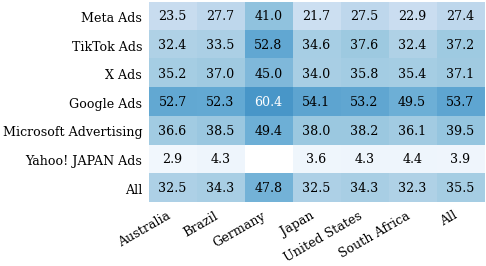

-> ./figures/fig01_banner.pdf
App. C Pairs with a banner: 3,545 / 10,000 (35.5%)
App. C Pairs with a banner, per platform: from 27 / 691 (3.9%) (Yahoo! JAPAN Ads) to 356 / 663 (53.7%) (Google Ads)
App. C Platforms for which Germany has the highest banner share: 5 of 5
App. C Meta Ads pairs with a banner, Germany: 68 / 166 (41.0%)
App. C Meta Ads pairs with a banner, other VPs: from 36 / 166 (21.7%) (Japan) to 46 / 166 (27.7%) (Brazil)
App. C Pairs with a banner, United States: 580 / 1,692 (34.3%)
App. C Pairs without a banner, Germany: 810 / 1,551 (52.2%)
App. C Pairs without a banner that store the AdClick-ID: 4,111 / 6,455 (63.7%)
App. C Pairs without a banner that store the AdClick-ID, per platform: from 236 / 664 (35.5%) (Yahoo! JAPAN Ads) to 671 / 802 (83.7%) (TikTok Ads)


In [6]:
# ============================== Figure 4 (fig01_banner) and Appendix C ==============================
name = "fig01_banner"; s = S(name)
piv = NI.pivot_table(index="platform", columns="country", values="banner", aggfunc="mean").reindex(index=PLATFORMS, columns=COUNTRIES)
piv["All"] = NI.groupby("platform").banner.mean().reindex(PLATFORMS)
piv.loc["All"] = list(NI.groupby("country").banner.mean().reindex(COUNTRIES)) + [NI.banner.mean()]
piv.index = [PL(p) for p in PLATFORMS] + ["All"]; piv.columns = list(CL) + ["All"]
fig, ax = plt.subplots(figsize=s["figsize"]); heat(ax, piv, s); save_fig(fig, name)

bk = lambda d: (int(d.banner.sum()), len(d))
show("App. C Pairs with a banner", *bk(NI))
show_range("App. C Pairs with a banner, per platform", {PL(p): bk(NI[NI.platform == p]) for p in PLATFORMS})
de_top = [p for p in PLATFORMS if "DE" in set(NI[NI.platform == p].country) and
          NI[(NI.platform == p) & (NI.country == "DE")].banner.mean() == NI[NI.platform == p].groupby("country").banner.mean().max()]
show("App. C Platforms for which Germany has the highest banner share",
     f"{len(de_top)} of {len([p for p in PLATFORMS if 'DE' in set(NI[NI.platform == p].country)])}")
show("App. C Meta Ads pairs with a banner, Germany", *bk(NI[(NI.platform == "FB") & (NI.country == "DE")]))
show_range("App. C Meta Ads pairs with a banner, other VPs", {COUNTRY_LABEL[c]: bk(NI[(NI.platform == "FB") & (NI.country == c)])
                                                              for c in COUNTRIES if c != "DE"})
show("App. C Pairs with a banner, United States", *bk(NI[NI.country == "US"]))
_de = NI[NI.country == "DE"]
show("App. C Pairs without a banner, Germany", int((~_de.banner).sum()), len(_de))
show("App. C Pairs without a banner that store the AdClick-ID", int(NB.stored.sum()), len(NB))
show_range("App. C Pairs without a banner that store the AdClick-ID, per platform",
           {PL(p): (int(NB[NB.platform == p].stored.sum()), int((NB.platform == p).sum())) for p in PLATFORMS})

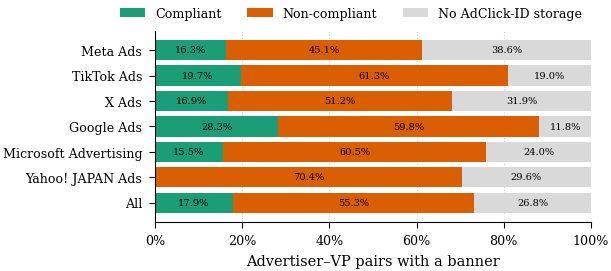

-> ./figures/fig02_compliance_platform.pdf
4.1.2 Pairs with a banner: 3,545 / 10,000 (35.5%)
4.1.2 Pairs without a banner that store the AdClick-ID: 4,111 / 6,455 (63.7%)
4.1.2 Consent sample (pairs): 3,459
4.1.2 Consent sample (distinct advertisers): 776
4.1.2 Pairs with a banner and a failed interaction (excluded): 86
4.1.2 Compliant: 619 / 3,459 (17.9%)
4.1.2 Non-compliant: 1,913 / 3,459 (55.3%)
4.1.2 No AdClick-ID storage: 927 / 3,459 (26.8%)
4.1.2 Store under all three interactions: 1,839 / 3,459 (53.2%)
4.1.2 Pairs storing the AdClick-ID that wait for accept all (compliant): 619 / 6,643 (9.3%)
4.1.2 Compliant, Google Ads: 98 / 346 (28.3%)
4.1.2 Compliant, Meta Ads / TikTok Ads / X Ads / Microsoft Advertising: from 129 / 830 (15.5%) (Microsoft Advertising) to 90 / 457 (19.7%) (TikTok Ads)
4.1.2 Compliant, Yahoo! JAPAN Ads: 0 / 27 (0.0%)


In [7]:
# ============================== Figure 2 (fig02_compliance_platform) and Section 4.1.2 ==============================
lvl = CAT.index.get_level_values("platform")
name = "fig02_compliance_platform"; s = S(name)
t = pd.crosstab(lvl, CAT, normalize="index").reindex(index=PLATFORMS, columns=CAT_ORDER).fillna(0)
t.loc["All"] = CAT.value_counts(normalize=True).reindex(CAT_ORDER).fillna(0)
fig, ax = plt.subplots(figsize=s["figsize"])
stacked(ax, t.iloc[::-1], s["colors"], s, labels=[PL(p) for p in t.index[::-1]])
style_ax(ax, s, percent_axis="x"); legend(ax, s); save_fig(fig, name)

n_cs = len(CAT)
show("4.1.2 Pairs with a banner", int(NI.banner.sum()), len(NI))
show("4.1.2 Pairs without a banner that store the AdClick-ID", len(nb_st), len(NB))
show("4.1.2 Consent sample (pairs)", n_cs)
show("4.1.2 Consent sample (distinct advertisers)", int(pd.Series([k[2] for k in CS]).nunique()))
show("4.1.2 Pairs with a banner and a failed interaction (excluded)", len(INCOMPLETE))
for g in CAT_ORDER:
    show(f"4.1.2 {g}", int((CAT == g).sum()), n_cs)
show("4.1.2 Store under all three interactions", int((W_ST.sum(1) == 3).sum()), n_cs)
n_store = len(nb_st) + int((CAT != "No AdClick-ID storage").sum())
show("4.1.2 Pairs storing the AdClick-ID that wait for accept all (compliant)", int((CAT == "Compliant").sum()), n_store)
cp = {p: (int(((lvl == p) & (CAT == "Compliant")).sum()), int((lvl == p).sum())) for p in PLATFORMS}
show("4.1.2 Compliant, Google Ads", *cp["GG"])
show_range("4.1.2 Compliant, Meta Ads / TikTok Ads / X Ads / Microsoft Advertising", {PL(p): cp[p] for p in ["FB", "TT", "TW", "MS"]})
show("4.1.2 Compliant, Yahoo! JAPAN Ads", *cp["YH"])

In [8]:
# ============================== Table 2 (Appendix D): compliance per platform and VP ==============================
cc = CAT.rename("cat").reset_index()
T2 = {}
for blk in ["Compliant", "Non-compliant", "Pairs"]:
    rows = {}
    for p in PLATFORMS:
        r = {}
        for c in COUNTRIES:
            x = cc[(cc.platform == p) & (cc.country == c)]
            r[COUNTRY_LABEL[c]] = "–" if len(x) == 0 else (f"{len(x):,}" if blk == "Pairs" else PCT((x.cat == blk).mean()))
        rows[PL(p)] = r
    T2[blk] = pd.DataFrame(rows).T
T2 = pd.concat(T2, names=["Block", "Platform"])
save_table(T2, "table2_compliance_platform_vp")

Australia Brazil Germany  Japan United States South Africa
Block         Platform                                                                        
Compliant     Meta Ads                  13.2%  17.8%   18.5%  16.7%         14.0%        16.2%
              TikTok Ads                19.4%  19.7%   21.3%  19.4%         17.5%        20.3%
              X Ads                     16.4%  17.1%   20.4%  15.7%         15.8%        14.8%
              Google Ads                26.8%  29.1%   34.8%  23.7%         26.3%        28.3%
              Microsoft Advertising     14.7%  14.1%   18.3%  17.7%         14.0%        13.6%
              Yahoo! JAPAN Ads           0.0%   0.0%       –   0.0%          0.0%         0.0%
Non-compliant Meta Ads                  47.4%  46.7%   36.9%  44.4%         51.2%        48.6%
              TikTok Ads                64.2%  57.6%   60.2%  62.5%         66.3%        56.3%
              X Ads                     51.6%  50.2%   49.5%  53.8%         50.6%        52.0%
              Google Ads                62.5%  58.2%   53.0%  64.4%         63.2%        58.5%
              Microsoft Advertising     63.6%  59.3%   57.1%  58.5%         64.0%        61.6%
              Yahoo! JAPAN Ads          75.0%  66.7%       –  80.0%         66.7%        66.7%
Pairs         Meta Ads                     38     45      65     36            43           37
              TikTok Ads                   67     66     108     72            80           64
              X Ads                       244    251     313    236           247          244
              Google Ads                   56     55      66     59            57           53
              Microsoft Advertising       129    135     175    130           136          125
              Yahoo! JAPAN Ads              4      6       –      5             6            6

-> ./tables/table2_compliance_platform_vp.csv


In [9]:
# ============================== Section 4.1.3: shadowing parameters ==============================
_SEG = re.compile(r"[*.~|,:;!]")
_URL0 = re.compile(r"^(?:(?:https?:)?//|(?:[a-z0-9-]+\.)+[a-z]{2,}(?::\d+)?[/?#])", re.I)


def multi_decode(url, max_rounds=5):
    previous = url
    for _ in range(max_rounds):
        decoded = unquote(previous)
        if decoded == previous:
            break
        previous = decoded
    return previous


def _b64(s):
    s = s.strip()
    if len(s) < 12 or not re.fullmatch(r"[A-Za-z0-9+/_=-]+", s):
        return None
    for dec in (base64.b64decode, base64.urlsafe_b64decode):
        try:
            t = dec(s + "=" * (-len(s) % 4)).decode("utf-8")
        except (binascii.Error, ValueError, UnicodeDecodeError):
            continue
        if t and sum(ch.isprintable() for ch in t) / len(t) > .9:
            return t
    return None


def _as_url(v):
    d = multi_decode(v)
    if _URL0.match(d):
        return d
    if re.match(r"^[/?]", d) and "=" in d:
        return "https://relative.invalid" + (d if d.startswith("/") else "/" + d)
    for x in (v, v[2:] if v[:2] == "a1" else None):
        t = _b64(x) if x else None
        if t and _URL0.match(multi_decode(t)):
            return multi_decode(t)
    return None


def url_leaves(url, depth=0):
    """Leaf parameters (name, value, host) of a URL; parameters that wrap a URL are opened recursively."""
    if not isinstance(url, str) or not url or depth > 4:
        return []
    sp = urlsplit(url.strip())
    ps = parse_qsl(sp.query, keep_blank_values=True)
    if "=" in sp.fragment:
        ps += parse_qsl(sp.fragment.lstrip("!/?"), keep_blank_values=True)
    for seg in sp.path.split("/"):
        ps += [tuple(x.split("=", 1)) for x in seg.split(";")[1:] if "=" in x]
    out, host = [], (sp.hostname or "").lower()
    for k, v in ps:
        u = _as_url(v)
        if u:
            out += url_leaves(u, depth + 1)
        else:
            out.append((multi_decode(k).strip().lower(), v, host))
    return out


def _variants(t):
    b = t.encode()
    return {"b64": {base64.b64encode(b).decode().rstrip("="), base64.urlsafe_b64encode(b).decode().rstrip("=")},
            "hash": {hashlib.md5(b).hexdigest(), hashlib.sha1(b).hexdigest(), hashlib.sha256(b).hexdigest()}}


def alias_encoding(v, toks):
    dv = multi_decode(v)
    for t, var in toks.items():
        if t in v:
            return "Plaintext"
        if t in dv:
            return "URL-encoded"
        if any(x in v or x in dv for x in var["b64"]):
            return "Base64"
        if any(t in (_b64(seg) or "") for seg in [dv] + _SEG.split(dv)):
            return "Base64"
        if any(h in dv.lower() for h in var["hash"]):
            return "Hashed"
    return None


AV = SITES.drop_duplicates("vid")[["vid", "country", "case", "platform", "adv", "domain_url", "reached_url"]].copy()
AV = AV[AV.set_index(KEY3).index.isin(POP)]
rows = []
for r in AV.itertuples(index=False):
    dname = CLICKID_NAME[r.platform]
    lv = {"adURL": url_leaves(r.domain_url), "final URL": url_leaves(r.reached_url)}
    toks = {v: None for w in lv.values() for k, v, _ in w if k == dname and len(multi_decode(v).strip()) >= ALIAS_MIN_LEN}
    toks = {multi_decode(t).strip(): _variants(multi_decode(t).strip()) for t in toks}
    if not toks:
        continue
    for where, w in lv.items():
        for k, v, h in w:
            if k == dname or not v:
                continue
            if company_of(h) == PLATFORM_ENTITY[r.platform]:
                continue                       # parameter of the platform's own redirect URL
            if re.search(r"(?:^|[?&;#/])" + re.escape(dname) + r"=", multi_decode(v), re.I):
                continue                       # the value wraps the default parameter
            e = alias_encoding(v, toks)
            if e:
                rows.append({"vid": r.vid, "country": r.country, "case": r.case, "platform": r.platform, "adv": r.adv, "where": where,
                             "param": k[:60], "encoding": e})
ALI = pd.DataFrame(rows, columns=["vid", "country", "case", "platform", "adv", "where", "param", "encoding"])
aflag = lambda d: pd.Series(POP.isin(pd.MultiIndex.from_frame(d[KEY3].drop_duplicates())).astype(int), index=POP)
FA = aflag(ALI)
show("4.1.3 Pairs with a shadowing parameter", int(FA.sum()), len(POP))
for p in PLATFORMS:
    show(f"4.1.3 Pairs with a shadowing parameter, {PL(p)}", int(FA[POP_PL == p].sum()), int((POP_PL == p).sum()))
for e in ["Plaintext", "URL-encoded", "Base64", "Hashed"]:
    show(f"4.1.3 Pairs with a shadowing parameter, {e}", int(aflag(ALI[ALI.encoding == e]).sum()))
PA = (ALI.drop_duplicates(KEY3 + ["param"]).groupby(["platform", "param"]).size().rename("pairs").reset_index()
      .sort_values(["platform", "pairs"], ascending=[True, False]))
for p in PLATFORMS:
    d = PA[PA.platform == p].head(5)
    if len(d):
        show(f"4.1.3 Shadowing parameters, {PL(p)}", ", ".join(f"{k} ({n:,} pairs)" for k, n in zip(d.param, d.pairs)))
show("4.1.3 Microsoft Advertising pairs with the msclkid in the gclid parameter", int(PA[(PA.platform == "MS") & (PA.param == "gclid")].pairs.sum()))
show("4.1 Key takeaway: pairs that store the AdClick-ID with no interaction (no banner or before the choice)", int(NI.stored.sum()), len(NI))

4.1.3 Pairs with a shadowing parameter: 252 / 10,000 (2.5%)
4.1.3 Pairs with a shadowing parameter, Meta Ads: 0 / 997 (0.0%)
4.1.3 Pairs with a shadowing parameter, TikTok Ads: 6 / 1,277 (0.5%)
4.1.3 Pairs with a shadowing parameter, X Ads: 0 / 4,221 (0.0%)
4.1.3 Pairs with a shadowing parameter, Google Ads: 30 / 663 (4.5%)
4.1.3 Pairs with a shadowing parameter, Microsoft Advertising: 216 / 2,151 (10.0%)
4.1.3 Pairs with a shadowing parameter, Yahoo! JAPAN Ads: 0 / 691 (0.0%)
4.1.3 Pairs with a shadowing parameter, Plaintext: 252
4.1.3 Pairs with a shadowing parameter, URL-encoded: 0
4.1.3 Pairs with a shadowing parameter, Base64: 0
4.1.3 Pairs with a shadowing parameter, Hashed: 0
4.1.3 Shadowing parameters, TikTok Ads: ttqid (6 pairs)
4.1.3 Shadowing parameters, Google Ads: utm_campaign (12 pairs), ef_id (6 pairs), gid (6 pairs), utm_content (6 pairs)
4.1.3 Shadowing parameters, Microsoft Advertising: aff_unique2 (30 pairs), gclid (30 pairs), ref_id (30 pairs), clickid (24 pairs), c

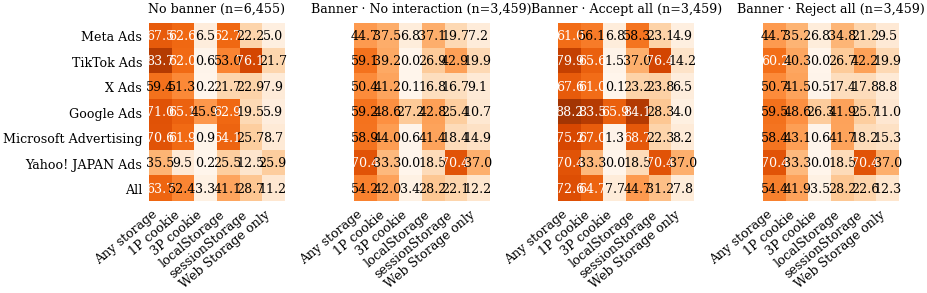

-> ./figures/fig05_storage.pdf
4.2.1 1P cookie, No banner, storing pairs: 3,382 / 4,111 (82.3%)
4.2.1 localStorage, No banner, storing pairs: 2,652 / 4,111 (64.5%)
4.2.1 sessionStorage, No banner, storing pairs: 1,855 / 4,111 (45.1%)
4.2.1 Web Storage only, No banner, storing pairs: 724 / 4,111 (17.6%)
4.2.1 1P cookie, Compliant, accept all, storing pairs: 584 / 619 (94.3%)
4.2.1 localStorage, Compliant, accept all, storing pairs: 344 / 619 (55.6%)
4.2.1 sessionStorage, Compliant, accept all, storing pairs: 170 / 619 (27.5%)
4.2.1 Web Storage only, Compliant, accept all, storing pairs: 35 / 619 (5.7%)
4.2.1 1P cookie, Non-compliant, no interaction, storing pairs: 1,452 / 1,875 (77.4%)
4.2.1 localStorage, Non-compliant, no interaction, storing pairs: 976 / 1,875 (52.1%)
4.2.1 sessionStorage, Non-compliant, no interaction, storing pairs: 765 / 1,875 (40.8%)
4.2.1 Web Storage only, Non-compliant, no interaction, storing pairs: 421 / 1,875 (22.5%)
4.2.1 3P cookie, Google Ads, no banner: 14

In [10]:
# ============================== Figure 5 (fig05_storage) and Section 4.2.1 ==============================
KINDS_S = {"1P cookie": "s_ck1p", "3P cookie": "s_ck3p", "localStorage": "s_local", "sessionStorage": "s_session"}
ck_ = OST.storage_type.eq("cookie")
OSTK = OST.assign(kind_s=np.select([ck_ & (OST.is_first_party == True), ck_ & (OST.is_first_party == False),
                                    OST.storage_type.eq("localStorage"), OST.storage_type.eq("sessionStorage")], list(KINDS_S), ""))
OSTK = OSTK[OSTK.kind_s != ""]
UST = union_adv(OSTK, "kind_s")
FSC = {k: sflags(UST, UST.kind_s == k) for k in KINDS_S}
FSC_ANY = {c: ADV[ADV["case"] == c].set_index(KEY3)["stored"].reindex(POP).fillna(0).astype(int) for c in CASE_ORDER}
_ck = {c: (FSC["1P cookie"][c] | FSC["3P cookie"][c]) for c in CASE_ORDER}
_ws = {c: (FSC["localStorage"][c] | FSC["sessionStorage"][c]) for c in CASE_ORDER}
FSC["Web Storage only"] = {c: (_ws[c] & (1 - _ck[c])).astype(int) for c in CASE_ORDER}
FSA = {"Any storage": FSC_ANY, **FSC}

name = "fig05_storage"; s5 = S(name)
_types = ["Any storage"] + list(KINDS_S) + ["Web Storage only"]
H5 = {st: pd.DataFrame({c: [sstat(FSA[c], st, None if p == "All" else p)[2] for p in ROWS] for c in _types}, index=[PL(p) for p in ROWS])
      for st in ST4}
state_heat(name, H5, s5)

# storage locations: denominator = pairs of the group that store the AdClick-ID in the reported visit
for g, c, gm in [("No banner", "no-interaction", STATE_MASK["No banner"]), ("Compliant, accept all", "accept-all", CAT_POP == "Compliant"),
                 ("Non-compliant, no interaction", "no-interaction", CAT_POP == "Non-compliant")]:
    st_m = gm & FSA["Any storage"][c].values.astype(bool)
    for k in ["1P cookie", "localStorage", "sessionStorage", "Web Storage only"]:
        show(f"4.2.1 {k}, {g}, storing pairs", int(FSA[k][c].values[st_m].sum()), int(st_m.sum()))
show("4.2.1 3P cookie, Google Ads, no banner", *sstat(FSA["3P cookie"], "No banner", "GG")[:2])
show_range("4.2.1 3P cookie, other platforms, no banner", {PL(p): sstat(FSA["3P cookie"], "No banner", p)[:2] for p in PLATFORMS if p != "GG"})
show("4.2.1 sessionStorage, TikTok Ads, no banner", *sstat(FSA["sessionStorage"], "No banner", "TT")[:2])
show("4.2.1 localStorage, Microsoft Advertising, no banner", *sstat(FSA["localStorage"], "No banner", "MS")[:2])
show("4.2.1 localStorage, Meta Ads, no banner", *sstat(FSA["localStorage"], "No banner", "FB")[:2])
show("4.2.1 Web Storage only, Yahoo! JAPAN Ads, no banner", *sstat(FSA["Web Storage only"], "No banner", "YH")[:2])

# VPs: storage and Web Storage only among storing pairs
any_nb = FSA["Any storage"]["no-interaction"].values.astype(bool)
wso_ni = FSA["Web Storage only"]["no-interaction"].values
vp_store = {COUNTRY_LABEL[c]: (int((STATE_MASK["No banner"] & (POP_CC == c) & any_nb).sum()), int((STATE_MASK["No banner"] & (POP_CC == c)).sum()))
            for c in COUNTRIES}
show_range("4.2.1 No banner, pairs storing the AdClick-ID, per VP", vp_store)
wso_vp = lambda gm, c, p=None: (lambda m: (int(wso_ni[m].sum()), int(m.sum())))(gm & any_nb & (POP_CC == c) & ((POP_PL == p) if p else True))
show_range("4.2.1 No banner, Web Storage only among storing pairs, per VP", {COUNTRY_LABEL[c]: wso_vp(STATE_MASK["No banner"], c) for c in COUNTRIES})
pl_de = [p for p in PLATFORMS if "DE" in set(POP_CC[POP_PL == p])]
de_hi = [p for p in pl_de if (lambda d: max(d, key=lambda c: d[c][0] / d[c][1] if d[c][1] else -1) == "DE")(
    {c: wso_vp(STATE_MASK["No banner"], c, p) for c in COUNTRIES})]
show("4.2.1 Platforms for which Germany has the highest Web Storage only share (no banner, storing pairs)", f"{len(de_hi)} of {len(pl_de)}")
show("4.2.1 Web Storage only, Microsoft Advertising, no banner, storing pairs, Germany", *wso_vp(STATE_MASK["No banner"], "DE", "MS"))
show_range("4.2.1 Web Storage only, Microsoft Advertising, no banner, storing pairs, other VPs",
           {COUNTRY_LABEL[c]: wso_vp(STATE_MASK["No banner"], c, "MS") for c in COUNTRIES if c != "DE"})
show("4.2.1 Web Storage only, non-compliant, no interaction, storing pairs, Germany", *wso_vp(CAT_POP == "Non-compliant", "DE"))
show_range("4.2.1 Web Storage only, non-compliant, no interaction, storing pairs, other VPs",
           {COUNTRY_LABEL[c]: wso_vp(CAT_POP == "Non-compliant", c) for c in COUNTRIES if c != "DE"})

4.2.2 Pairs storing the AdClick-ID [No banner]: 4,111 / 6,455 (63.7%)
4.2.2 Pairs storing the AdClick-ID [Banner · NI]: 1,875 / 3,459 (54.2%)
4.2.2 Pairs storing the AdClick-ID [Banner · A]: 2,511 / 3,459 (72.6%)
4.2.2 Pairs storing the AdClick-ID [Banner · R]: 1,882 / 3,459 (54.4%)
4.2.2 Accept all adds storage (of pairs not storing with no interaction): 651 / 1,584 (41.1%)
4.2.2 Still stored under reject all (of pairs storing with no interaction): 1,844 / 1,875 (98.3%)
4.2.2 Same entry with no interaction and under reject all (of pairs storing under both): 1,833 / 1,844 (99.4%)


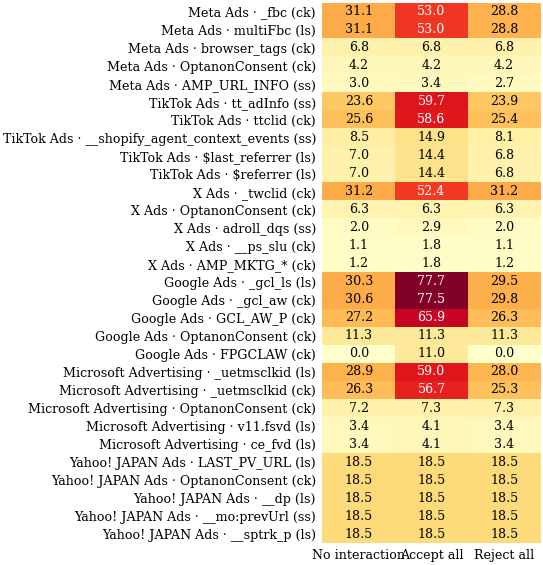

-> ./figures/fig08b_top_entries_by_case.pdf
4.2.2 Google Ads, _gcl_aw (ck), No interaction: 106 / 346 (30.6%)
4.2.2 Google Ads, _gcl_aw (ck), Accept all: 268 / 346 (77.5%)
4.2.2 Google Ads, _gcl_aw (ck), Reject all: 103 / 346 (29.8%)
4.2.2 Google Ads, OptanonConsent (ck), No interaction: 39 / 346 (11.3%)
4.2.2 Google Ads, OptanonConsent (ck), Accept all: 39 / 346 (11.3%)
4.2.2 Google Ads, OptanonConsent (ck), Reject all: 39 / 346 (11.3%)


In [11]:
# ============================== Section 4.2.2 and Figure 6 (fig08b_top_entries_by_case) ==============================
show4("4.2.2 Pairs storing the AdClick-ID", FSC_ANY)
m = smask("Banner · NI")
ni, a_, r_ = (FSC_ANY[c].values.astype(bool) & m for c in CASE_ORDER)
nni = ~FSC_ANY["no-interaction"].values.astype(bool) & m
show("4.2.2 Accept all adds storage (of pairs not storing with no interaction)", int((nni & a_).sum()), int(nni.sum()))
show("4.2.2 Still stored under reject all (of pairs storing with no interaction)", int((ni & r_).sum()), int(ni.sum()))

ABBR = {"cookie": "ck", "localStorage": "ls", "sessionStorage": "ss"}
OSTC = OST.assign(entry=OST["name"].map(norm_name) + " (" + OST.storage_type.map(ABBR).fillna("?") + ")")
OSTC = OSTC.drop(columns=[c for c in KEY if c in OSTC]).join(VKEY, on="vid")
OSTC = OSTC[OSTC.set_index(KEY3).index.isin(CS)]
EA = occ_to_adv(OSTC, "entry")
ES = {c: EA[EA["case"] == c].groupby(KEY3).entry.agg(set) for c in CASE_ORDER}
E_NI, E_R = (ES[c].reindex(CS).map(lambda x: x if isinstance(x, set) else set()) for c in ["no-interaction", "reject-all"])
both_nr = W_ST["no-interaction"].eq(1) & W_ST["reject-all"].eq(1)
k_same = int(pd.Series([bool(x & y) for x, y in zip(E_NI, E_R)], index=CS)[both_nr].sum())
show("4.2.2 Same entry with no interaction and under reject all (of pairs storing under both)", k_same, int(both_nr.sum()))

name = "fig08b_top_entries_by_case"; s = S(name)
A8b = EA[EA.set_index(KEY3).index.isin(CS)]
CS_N = pd.Series([k[1] for k in CS]).value_counts().reindex(PLATFORMS)
cnt8 = (A8b.drop_duplicates(KEY3 + ["case", "entry"]).groupby(["platform", "entry", "case"]).size()
        .unstack("case").reindex(columns=CASE_ORDER).fillna(0))
sh8 = cnt8.div(cnt8.index.get_level_values("platform").map(CS_N).values, axis=0)
top8 = pd.concat([sh8.loc[p].assign(mx=sh8.loc[p].max(1)).sort_values("mx", ascending=False).head(s["top_per_platform"]).assign(platform=p)
                  for p in PLATFORMS if p in sh8.index.get_level_values("platform") and CS_N.get(p, 0) >= MIN_N])
lab8 = [f"{PL(p)} · " + (e if len(e) <= s["max_label"] else e[:s["max_label"] - 1] + "…") for p, e in zip(top8.platform, top8.index)]
piv8 = pd.DataFrame(top8[CASE_ORDER].values, index=lab8, columns=[CASE_LABEL[c] for c in CASE_ORDER])
fig, ax = plt.subplots(figsize=s["figsize"]); heat(ax, piv8, s, vmin=0, vmax=max(float(piv8.values.max()), 1e-9)); save_fig(fig, name)

for e in ["_gcl_aw (ck)", "OptanonConsent (ck)"]:
    for c in CASE_ORDER:
        k = int(cnt8.loc[("GG", e), c]) if ("GG", e) in cnt8.index else 0
        show(f"4.2.2 Google Ads, {e}, {CASE_LABEL[c]}", k, int(CS_N["GG"]))

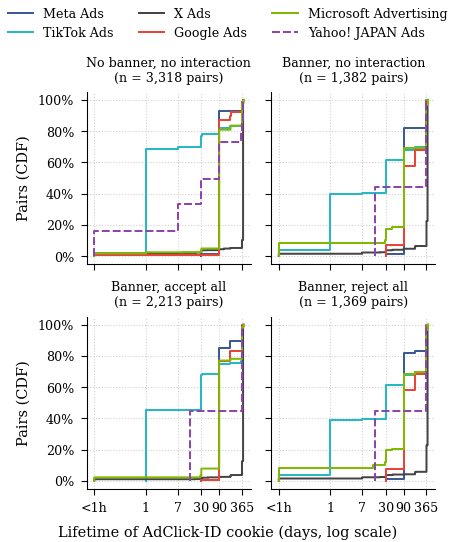

-> ./figures/fig07_lifetime.pdf
App. F More than one year, no banner: 1,272 / 3,318 (38.3%)
App. F More than one year, compliant, accept all: 235 / 582 (40.4%)
App. F More than one year, non-compliant, no interaction: 498 / 1,382 (36.0%)
App. F More than one year, X Ads, no banner: 1,221 / 1,360 (89.8%)
App. F Median lifetime (days), X Ads, no banner: 390
App. F One day or less, TikTok Ads, no banner: 313 / 456 (68.6%)
App. F Median lifetime (days), Meta Ads, no banner: 90
App. F Median lifetime (days), Google Ads, no banner: 90
App. F Median lifetime (days), Microsoft Advertising, no banner: 90


In [12]:
# ============================== Figure 7 (fig07_lifetime) and Appendix F ==============================
CKo = OST[(OST.storage_type == "cookie") & (OST.is_first_party == True)].copy()
CKo["cookie"] = CKo["name"].map(norm_name)
CKu = CKo.drop(columns=[c for c in KEY if c in CKo]).join(VKEY, on="vid")
Ru = CKu.merge(occ_to_adv(CKu, "cookie"), on=KEY + ["cookie"])
LTC = Ru.groupby(KEY3 + ["case"]).agg(lifetime=("lifetime_days", "max")).reset_index()
LTC = LTC[LTC.set_index(KEY3).index.isin(POP)]
LT_ANY = LTC.set_index(KEY3 + ["case"]).lifetime.rename("lt")       # NaN = session cookies only


def life_x(st, p=None, extra=None):
    """Longest lifetime of a persistent first-party AdClick-ID cookie per pair in the visit."""
    lt = svalues(LT_ANY, st, p, None, extra)
    return lt[~np.isnan(lt)]


LIFE = {(st, p): life_x(st, None if p == "All" else p) for st in ST4 for p in ROWS}

name = "fig07_lifetime"; s = S(name)
fig, axes = plt.subplots(2, 2, figsize=s["figsize"], sharex=True, sharey=True, constrained_layout=True)
for i, (ax, st) in enumerate(zip(axes.flat, ST4)):
    for p in PLATFORMS:
        x = np.sort(np.clip(LIFE[(st, p)], s["min_days"], None))
        if len(x) < MIN_N:
            continue
        ax.step(np.r_[x[0], x], np.r_[0, np.arange(1, len(x) + 1) / len(x)], where="post",
                color=s["color_override"].get(p, s["colors"].get(p)), lw=s["lw"], linestyle=s["linestyles"].get(p, "-"), label=PL(p))
    ax.set_xscale("log"); ax.set_xticks([s["min_days"]] + s["xticks"])
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: "<1h" if np.isclose(v, s["min_days"]) else f"{v:g}"))
    ax.xaxis.set_minor_locator(mticker.NullLocator())
    ax.set_title(f"{STATE_TITLE[st]}\n(n = {len(LIFE[(st, 'All')]):,} pairs)", fontsize=STYLE["font_size"] - 1)
    style_ax(ax, {**s, "ylabel": s["ylabel"] if i % 2 == 0 else None, "xlabel": None, "xtick_rotation": 0})
fig.supxlabel(s["xlabel"], fontsize=STYLE["font_size"])
h, l = axes.flat[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=s["legend_ncol"], frameon=False, fontsize=s["legend_size"])
save_fig(fig, name)

yr = lambda x: (int((x > 366).sum()), len(x))
show("App. F More than one year, no banner", *yr(LIFE[("No banner", "All")]))
show("App. F More than one year, compliant, accept all", *yr(life_x("Banner · A", extra=CAT_POP == "Compliant")))
show("App. F More than one year, non-compliant, no interaction", *yr(life_x("Banner · NI", extra=CAT_POP == "Non-compliant")))
x_tw = LIFE[("No banner", "TW")]
show("App. F More than one year, X Ads, no banner", *yr(x_tw))
show("App. F Median lifetime (days), X Ads, no banner", f"{np.median(x_tw):.0f}")
x_tt = LIFE[("No banner", "TT")]
show("App. F One day or less, TikTok Ads, no banner", int((x_tt <= 1.01).sum()), len(x_tt))
for p in ["FB", "GG", "MS"]:
    show(f"App. F Median lifetime (days), {PL(p)}, no banner", f"{np.median(LIFE[('No banner', p)]):.0f}")

In [13]:
# ============================== Recipients: Table 3 and Section 4.3 ==============================
R5 = REQ.copy()
_host = R5.host.astype(str).str.lower(); _adv = R5.vid.map(VKEY.adv).astype(str)
_is1 = R5.recipient_class.eq("first_party").values
R5["endpoint"] = [(h[: -len(a)] + "<adv>") if h.endswith(a) else h for h, a in zip(_host, _adv)]
_land = SITES.set_index("vid")["reached_host"].astype(str).str.lower()
R5["host_kind"] = np.where(_host.values == _land.reindex(R5.vid).values, "Landing-page host", "Other advertiser host")
R5["domain"] = [("google.<ccTLD>" if (_GCC.match(d) and d != "google.com") else d) for d in R5.etld1.astype(str)]
R5["company"] = np.where(_is1, "first_party", [company_of(h, e) for h, e in zip(R5.host, R5.etld1)])
R5["entry"] = np.where(_is1, "1P|" + R5.host_kind + "|" + R5.endpoint, "3P|" + R5.domain)
UE = union_adv(R5, "entry").join(R5.drop_duplicates("entry").set_index("entry")[["company", "endpoint", "host_kind", "domain"]], on="entry")
CLASSES = ["First-party tracking domains", "Ad platform tracking domains", "Third-party tracking domains"]
UE["cls"] = np.select([UE.company.eq("first_party"), UE.company.ne("other")], CLASSES[:2], CLASSES[2])
UE["sub"] = np.where(UE.cls.ne("Ad platform tracking domains"), "",
                     np.where(UE.company.eq(UE.platform.map(PLATFORM_ENTITY)), "Own-platform tracking domains", "Cross-platform tracking domains"))
UFC = {"Any tracking domain": sflags(UE), **{c: sflags(UE, UE.cls == c) for c in CLASSES},
       **{c: sflags(UE, UE["sub"] == c) for c in ["Own-platform tracking domains", "Cross-platform tracking domains"]}}
UFC["Google, AdClick-ID of another platform"] = {c: (sflags(UE, UE.company == "google")[c] & (POP_PL != "GG")).astype(int) for c in CASE_ORDER}
RCLS = ["Any tracking domain", "Ad platform tracking domains", "Own-platform tracking domains", "Cross-platform tracking domains",
        "Google, AdClick-ID of another platform", "First-party tracking domains", "Third-party tracking domains"]
U11 = UE[UE.cls == "First-party tracking domains"].reset_index(drop=True)
U12 = UE[UE.cls == "Third-party tracking domains"].reset_index(drop=True)
NOT_GG = POP_PL != "GG"
_ex = lambda k: NOT_GG if k.startswith("Google") else None

VISIT_COLS = {"No banner": "No banner", "Banner · NI": "No interaction", "Banner · A": "Accept all", "Banner · R": "Reject all"}
T3 = pd.DataFrame({f"{VISIT_COLS[st]} ({int(STATE_MASK[st].sum()):,})": [PCT(sstat(UFC[k], st, extra=_ex(k))[2]) for k in RCLS] for st in ST4},
                  index=[k.replace(" tracking domains", "") if k.startswith(("Own", "Cross")) else k for k in RCLS])
T3.index.name = "Recipient"
save_table(T3, "table3_recipients")
show("Table 3 Google row denominators", f"{sstat(UFC[RCLS[4]], 'No banner', extra=NOT_GG)[1]:,} / {sstat(UFC[RCLS[4]], 'Banner · NI', extra=NOT_GG)[1]:,}")

F_any = UFC["Any tracking domain"]
show4("4.3 Any tracking domain", F_any)
ni_s, r_s = (F_any[c].values.astype(bool) & smask("Banner · NI") for c in ["no-interaction", "reject-all"])
show("4.3 Still sent under reject all (of pairs sending with no interaction)", int((ni_s & r_s).sum()), int(ni_s.sum()))
show("4.3 Sent without storing, no banner", *sstat(F_any, "No banner", extra=FSC_ANY["no-interaction"].values == 0)[:2])
show("4.3 Sent, no-storage pairs, no interaction", *sstat(F_any, "Banner · NI", extra=CAT_POP == "No AdClick-ID storage")[:2])
show("4.3 Sent, compliant, no interaction", *sstat(F_any, "Banner · NI", extra=CAT_POP == "Compliant")[:2])
show("4.3 Sent, compliant, reject all", *sstat(F_any, "Banner · R", extra=CAT_POP == "Compliant")[:2])

,"No banner (6,455)","No interaction (3,459)","Accept all (3,459)","Reject all (3,459)"
Recipient,,,,
Any tracking domain,85.3%,77.5%,86.5%,77.8%
Ad platform tracking domains,74.4%,60.6%,79.6%,61.2%
Own-platform,44.8%,33.1%,57.5%,33.3%
Cross-platform,69.1%,56.3%,74.5%,56.7%
"Google, AdClick-ID of another platform",69.1%,57.4%,74.4%,57.9%
First-party tracking domains,43.9%,44.0%,47.2%,43.9%
Third-party tracking domains,56.7%,48.7%,58.8%,49.0%


-> ./tables/table3_recipients.csv
Table 3 Google row denominators: 6,148 / 3,113
4.3 Any tracking domain [No banner]: 5,508 / 6,455 (85.3%)
4.3 Any tracking domain [Banner · NI]: 2,679 / 3,459 (77.5%)
4.3 Any tracking domain [Banner · A]: 2,993 / 3,459 (86.5%)
4.3 Any tracking domain [Banner · R]: 2,691 / 3,459 (77.8%)
4.3 Still sent under reject all (of pairs sending with no interaction): 2,665 / 2,679 (99.5%)
4.3 Sent without storing, no banner: 1,464 / 2,344 (62.5%)
4.3 Sent, no-storage pairs, no interaction: 472 / 927 (50.9%)
4.3 Sent, compliant, no interaction: 413 / 619 (66.7%)
4.3 Sent, compliant, reject all: 415 / 619 (67.0%)


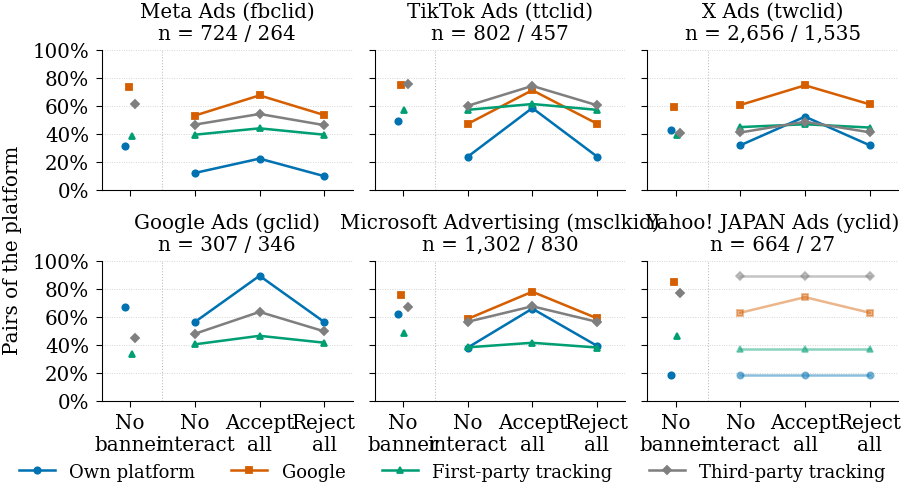

-> ./figures/fig10_crossplatform.pdf
4.3.1 Cross-platform, no banner: 4,460 / 6,455 (69.1%)
4.3.1 Own platform, no banner: 2,894 / 6,455 (44.8%)
4.3.1 Google receives the AdClick-ID of another platform, no banner: 4,248 / 6,148 (69.1%)
4.3.1 Platforms whose AdClick-ID reaches Google more often than the own platform, no banner: 5 of 5
4.3.1 Google receives the fbclid, no banner: 530 / 724 (73.2%)
4.3.1 Meta Ads: own platform receives the fbclid, no banner: 225 / 724 (31.1%)
4.3.1 Google receives the yclid, no banner: 562 / 664 (84.6%)
4.3.1 Yahoo! JAPAN Ads: own platform receives the yclid, no banner: 123 / 664 (18.5%)
4.3.1 Own platform, compliant [Banner · NI]: 43 / 619 (6.9%)
4.3.1 Own platform, compliant [Banner · A]: 521 / 619 (84.2%)
4.3.1 Own platform, compliant [Banner · R]: 49 / 619 (7.9%)
4.3.1 Cross-platform, compliant [Banner · NI]: 224 / 619 (36.2%)
4.3.1 Cross-platform, compliant [Banner · R]: 226 / 619 (36.5%)
4.3.1 Cross-platform, non-compliant [Banner · NI]: 1,411 / 1,9

In [14]:
# ============================== Figure 3 (fig10_crossplatform) and Section 4.3.1 ==============================
import matplotlib.ticker as mtick
ENTS = [e for e in ["first_party", "google", "meta", "microsoft", "tiktok", "twitter", "yahoo", "other"] if (UE.company == e).any()]
FEC = {e: sflags(UE, UE.company == e) for e in ENTS}

VISIT_LABEL = {"No banner": "No\nbanner", "Banner · NI": "No\ninteract", "Banner · A": "Accept\nall", "Banner · R": "Reject\nall"}
FS_AX = 13
SERIES = [  # (label, receiving company for the platform, color, marker, horizontal offset of the No banner point)
    ("Own platform",         lambda p: PLATFORM_ENTITY[p], "#0072B2", "o", -0.06),
    ("Google",               lambda p: "google",           "#D55E00", "s", -0.02),
    ("First-party tracking", lambda p: "first_party",      "#009E73", "^",  0.02),
    ("Third-party tracking", lambda p: "other",            "#7F7F7F", "D",  0.06),
]
SMALL_N = {"YH"}
X_POS = np.array([0, 0.8, 1.6, 2.4])
name = "fig10_crossplatform"; s = S(name)
fig, axes = plt.subplots(2, 3, figsize=s["figsize"], sharex=True, sharey=True, constrained_layout=True)
for ax, p in zip(axes.flat, PLATFORMS):
    alpha = 0.45 if p in SMALL_N else 1.0
    for lab, comp, col, mk, dx in SERIES:
        e = comp(p)
        if lab == "Google" and e == PLATFORM_ENTITY[p]:
            continue
        y = np.array([sstat(FEC[e], st, p)[2] for st in ST4], float)
        ax.plot(X_POS[1:], y[1:], color=col, lw=1.4, marker=mk, ms=3.5, alpha=alpha, label=lab)
        ax.plot(X_POS[:1] + dx, y[:1], color=col, marker=mk, ms=3.5, ls="none")
    ax.axvline(0.4, color="#BDBDBD", lw=0.6, ls=":")
    ax.set_xlim(-0.35, 2.75)
    n_nb, n_cs_p = int(smask("No banner", p).sum()), int(smask("Banner · NI", p).sum())
    ax.set_title(f"{PL(p)} ({CLICKID_NAME[p]})\nn = {n_nb:,} / {n_cs_p:,}", fontsize=FS_AX - 2)
    ax.set_ylim(0, 1); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    ax.tick_params(axis="y", labelsize=FS_AX - 2); ax.set_yticks([0, .2, .4, .6, .8, 1])
    ax.grid(axis="y", ls=":", lw=0.5, alpha=0.6); ax.grid(axis="x", visible=False)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
for ax in axes[-1]:
    ax.set_xticks(X_POS); ax.set_xticklabels([VISIT_LABEL[st] for st in ST4], fontsize=FS_AX - 2)
fig.supylabel("Pairs of the platform", fontsize=FS_AX - 2)
h, l = axes.flat[0].get_legend_handles_labels()
fig.legend(h, l, loc="outside lower center", ncol=4, frameon=False, fontsize=FS_AX - 3)
save_fig(fig, name)

show("4.3.1 Cross-platform, no banner", *sstat(UFC["Cross-platform tracking domains"], "No banner")[:2])
show("4.3.1 Own platform, no banner", *sstat(UFC["Own-platform tracking domains"], "No banner")[:2])
show("4.3.1 Google receives the AdClick-ID of another platform, no banner",
     *sstat(UFC["Google, AdClick-ID of another platform"], "No banner", extra=NOT_GG)[:2])
gg_win = [p for p in PLATFORMS if p != "GG" and sstat(FEC["google"], "No banner", p)[0] > sstat(FEC[PLATFORM_ENTITY[p]], "No banner", p)[0]]
show("4.3.1 Platforms whose AdClick-ID reaches Google more often than the own platform, no banner", f"{len(gg_win)} of {len(PLATFORMS) - 1}")
for p in ["FB", "YH"]:
    show(f"4.3.1 Google receives the {CLICKID_NAME[p]}, no banner", *sstat(FEC["google"], "No banner", p)[:2])
    show(f"4.3.1 {PL(p)}: own platform receives the {CLICKID_NAME[p]}, no banner", *sstat(FEC[PLATFORM_ENTITY[p]], "No banner", p)[:2])
for st in ST4[1:]:
    show(f"4.3.1 Own platform, compliant [{st}]", *sstat(UFC["Own-platform tracking domains"], st, extra=CAT_POP == "Compliant")[:2])
for g in ["Compliant", "Non-compliant"]:
    for st in ["Banner · NI", "Banner · R"]:
        show(f"4.3.1 Cross-platform, {g.lower()} [{st}]", *sstat(UFC["Cross-platform tracking domains"], st, extra=CAT_POP == g)[:2])

In [15]:
# ============================== Table 4 and Section 4.3.2 ==============================
def top_visit_table(U, label, top_n=20):
    C = label_state_counts(U, label)
    N = {st: int(STATE_MASK[st].sum()) for st in ST4}
    order = C.div(pd.Series(N), axis=1).max(1).sort_values(ascending=False).head(top_n).index
    return pd.DataFrame({VISIT_COLS[st]: [PCT(C.loc[o, st] / N[st]) for o in order] for st in ST4}, index=[str(o) for o in order])


T4 = pd.concat({"First-party": top_visit_table(U11, "endpoint"), "Third-party": top_visit_table(U12, "domain")}, names=["Class", "Tracking domain"])
save_table(T4, "table4_top_tracking_domains")

show4("4.3.2 First-party tracking domains", UFC["First-party tracking domains"])
for g in ["Non-compliant", "Compliant", "No AdClick-ID storage"]:
    show(f"4.3.2 First-party tracking domains, {g.lower()}, no interaction",
         *sstat(UFC["First-party tracking domains"], "Banner · NI", extra=CAT_POP == g)[:2])

# ---- server-side GTM (SST-Guard label on first-party requests; plaintext query strings only) ----
P = PRM[PRM.recipient_class.eq("first_party") & PRM.sst_flag & ~PRM.sst_decoded]
V = SSTV.copy()
for c in ["n_sst_requests", "n_sst_decoded"]:
    V[c] = pd.to_numeric(V[c], errors="coerce").fillna(0)
V = V[V.served_by.eq("first_party") & ((V.n_sst_requests - V.n_sst_decoded) > 0)]
fAC = sflags(union_adv(V.assign(sst="sGTM"), "sst"))              # sGTM present in the visit
fBC = sflags(union_adv(P.assign(sst="sGTM+ID"), "sst"))           # sGTM receives the AdClick-ID
show4("4.3.2 sGTM receives the AdClick-ID", fBC)
show("4.3.2 sGTM receives the AdClick-ID, compliant, no interaction", *sstat(fBC, "Banner · NI", extra=CAT_POP == "Compliant")[:2])
own = UFC["Own-platform tracking domains"]
show("4.3.2 Own platform receives the AdClick-ID, no banner, pairs where sGTM receives it",
     *sstat(own, "No banner", extra=fBC["no-interaction"].values == 1)[:2])
show("4.3.2 Own platform receives the AdClick-ID, no banner, pairs without sGTM", *sstat(own, "No banner", extra=fAC["no-interaction"].values == 0)[:2])

No banner No interaction Accept all Reject all
Class       Tracking domain                                                      
First-party www.<adv>                  13.7%          18.3%      18.6%      18.1%
            <adv>                      18.1%          15.0%      15.2%      14.9%
            gtm.<adv>                   0.3%           1.4%       1.6%       1.4%
            analytics.<adv>             0.3%           1.0%       1.2%       1.0%
            sgtm.<adv>                  0.1%           0.9%       1.1%       0.9%
            sst.<adv>                   0.1%           0.6%       1.0%       0.6%
            smetrics.<adv>              0.3%           0.3%       0.9%       0.5%
            sb.<adv>                    0.9%           0.0%       0.0%       0.0%
            t.<adv>                     0.1%           0.7%       0.7%       0.7%
            metrics.<adv>               0.4%           0.4%       0.6%       0.4%
            unagi.<adv>                 0.6%           0.1%       0.2%       0.2%
            shop.<adv>                  0.6%           0.0%       0.0%       0.0%
            info.<adv>                  0.2%           0.2%       0.5%       0.2%
            tracking.<adv>              0.0%           0.3%       0.5%       0.3%
            go.<adv>                    0.4%           0.4%       0.4%       0.4%
            data.<adv>                  0.0%           0.4%       0.4%       0.4%
            events.<adv>                0.1%           0.4%       0.4%       0.4%
            app.<adv>                   0.4%           0.0%       0.0%       0.0%
            collect.<adv>               0.0%           0.2%       0.3%       0.2%
            tagging.<adv>               0.2%           0.2%       0.3%       0.2%
Third-party line.me                     8.4%           1.1%       1.4%       1.1%
            smartnews-ads.com           7.3%           0.1%       0.2%       0.1%
            taboola.com                 6.6%           3.1%       6.8%       2.7%
            pinterest.com               6.5%           3.7%       6.5%       3.5%
            adsrvr.org                  4.9%           3.3%       6.4%       3.3%
            criteo.com                  5.4%           3.9%       6.1%       3.8%
            hubspot.com                 3.2%           3.4%       5.3%       3.4%
            outbrain.com                3.5%           1.6%       4.8%       1.5%
            ladsp.com                   4.5%           0.1%       0.2%       0.1%
            snapchat.com                3.8%           2.4%       4.3%       2.3%
            klaviyo.com                 4.1%           1.6%       2.0%       1.7%
            cloudflareinsights.com      3.8%           0.7%       0.7%       0.7%
            im-apps.net                 3.5%           0.1%       0.1%       0.1%
            creativecdn.com             2.4%           1.4%       3.1%       1.4%
            sp-trk.com                  3.1%           0.3%       0.3%       0.3%
            mysquadbeyond.com           3.0%           0.0%       0.0%       0.0%
            amplitude.com               0.9%           2.2%       3.0%       2.2%
            stackadapt.com              1.1%           1.5%       2.9%       1.4%
            teads.tv                    0.9%           1.0%       2.7%       0.9%
            mktoresp.com                1.1%           1.5%       2.5%       1.3%

-> ./tables/table4_top_tracking_domains.csv
4.3.2 First-party tracking domains [No banner]: 2,835 / 6,455 (43.9%)
4.3.2 First-party tracking domains [Banner · NI]: 1,521 / 3,459 (44.0%)
4.3.2 First-party tracking domains [Banner · A]: 1,631 / 3,459 (47.2%)
4.3.2 First-party tracking domains [Banner · R]: 1,519 / 3,459 (43.9%)
4.3.2 First-party tracking domains, non-compliant, no interaction: 1,065 / 1,913 (55.7%)
4.3.2 First-party tracking domains, compliant, no interaction: 216 / 619 (34.9%)
4.3.2 First-party tracking domains, no adclick-id storage, no interaction: 240 / 927 (25.9%)
4.3.2 sGTM receives the AdClick-ID [No banner]: 442 / 6,455 (6.8%)
4.3.2 sGTM receives the AdClick-ID [Banner · NI]: 389 / 3,459 (11.2%)
4.3.2 sGTM receives the AdClick-ID [Banner · A]: 509 / 3,459 (14.7%)
4.3.2 sGTM receives the AdClick-ID [Banner · R]: 394 / 3,459 (11.4%)
4.3.2 sGTM receives the AdClick-ID, compliant, no interaction: 57 / 619 (9.2%)
4.3.2 Own platform receives the AdClick-ID, no banner, 

4.3.3 Third-party tracking domains [No banner]: 3,661 / 6,455 (56.7%)
4.3.3 Third-party tracking domains [Banner · NI]: 1,685 / 3,459 (48.7%)
4.3.3 Third-party tracking domains [Banner · A]: 2,033 / 3,459 (58.8%)
4.3.3 Third-party tracking domains [Banner · R]: 1,694 / 3,459 (49.0%)
4.3.3 Third-party domains under both accept all and reject all (all pairs of the consent sample): 529 / 643 (82.3%)
4.3.3 Third-party domains under both accept all and reject all (compliant pairs of the consent sample): 59 / 184 (32.1%)


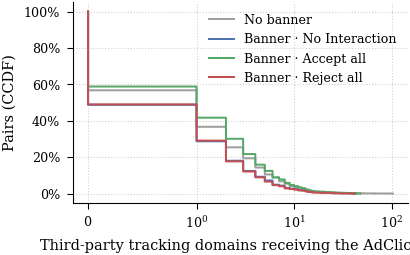

-> ./figures/fig12b_3p_ccdf.pdf
App. G Ten or more third-party tracking domains, no banner: 263 / 6,455 (4.1%)


,Domain,Pairs
#,,
1,taboola.com,658
2,pinterest.com,646
3,line.me,587
4,criteo.com,558
5,adsrvr.org,541
6,smartnews-ads.com,474
7,outbrain.com,397
8,hubspot.com,389
9,ladsp.com,294


-> ./tables/table5_3p_all_platforms.csv
4.3.3 Third-party tracking domains receiving the AdClick-ID of all six platforms: 21 / 908 (2.3%)
4.3.3 openai.com (pairs): 79


In [16]:
# ============================== Section 4.3.3, Figure 8 (fig12b_3p_ccdf) and Table 5 ==============================
show4("4.3.3 Third-party tracking domains", UFC["Third-party tracking domains"])

# domain level, consent sample: domains under accept all and/or reject all
_u = U12[U12.set_index(KEY3).index.isin(CS)]
for g in ["All", "Compliant"]:
    d = _u if g == "All" else _u[[x in set(CAT.index[CAT == g]) for x in map(tuple, _u[KEY3].values)]]
    A_ = set(d[d["case"] == "accept-all"].domain); R_ = set(d[d["case"] == "reject-all"].domain)
    show(f"4.3.3 Third-party domains under both accept all and reject all ({g.lower()} pairs of the consent sample)", len(A_ & R_), len(A_ | R_))

N3 = U12.drop_duplicates(KEY3 + ["case", "domain"]).groupby(KEY3 + ["case"]).size().rename("n3")
n3_vals = lambda st: np.nan_to_num(svalues(N3.astype(float), st), nan=0.0)
name = "fig12b_3p_ccdf"; s = S(name)
fig, ax = plt.subplots(figsize=s["figsize"])
for st in ST4:
    x = np.sort(n3_vals(st))
    if len(x) >= MIN_N:
        ax.step(np.r_[0, x], np.r_[1, 1 - np.arange(len(x)) / len(x)], where="post", color=STATE_COLORS[st], lw=s["lw"],
                label=f"{s['titles'].get(st, st)}")
style_ax(ax, s); ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0)); ax.set_xscale("symlog", linthresh=1)
legend(ax, s); save_fig(fig, name)
v_nb = n3_vals("No banner")
show("App. G Ten or more third-party tracking domains, no banner", int((v_nb >= 10).sum()), len(v_nb))

# Table 5: third-party tracking domains receiving the AdClick-ID of all six platforms under all three interactions (four visits only)
_keep = np.zeros(len(U12), bool)
for _st in ST4:
    _k = set(POP[STATE_MASK[_st]])
    _keep |= np.array([(k in _k) and (c == STATE_CASE[_st]) for k, c in zip(map(tuple, U12[KEY3].values), U12["case"])])
D21 = U12[_keep]
S21 = (D21.drop_duplicates(KEY3 + ["domain"]).groupby("domain").size().rename("Pairs").to_frame()
       .join(D21.groupby("domain").agg(n_plat=("platform", "nunique"), n_case=("case", "nunique"))))
T5 = S21[(S21.n_plat == len(PLATFORMS)) & (S21.n_case == len(CASE_ORDER))].sort_values("Pairs", ascending=False).reset_index()
T5.insert(0, "#", range(1, len(T5) + 1))
save_table(T5[["#", "domain", "Pairs"]].rename(columns={"domain": "Domain"}).set_index("#"), "table5_3p_all_platforms")
show("4.3.3 Third-party tracking domains receiving the AdClick-ID of all six platforms", len(T5), len(S21))
show("4.3.3 openai.com (pairs)", int(S21.Pairs.get("openai.com", 0)))

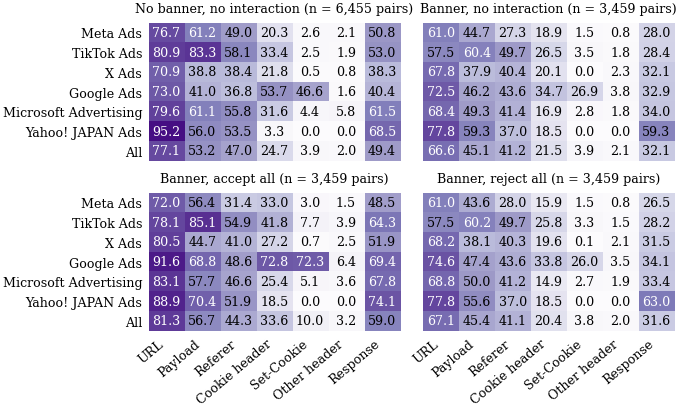

-> ./figures/figA_channels.pdf
App. H URL, no banner: 4,978 / 6,455 (77.1%)
App. H Payload, no banner: 3,434 / 6,455 (53.2%)
App. H Referer, no banner: 3,035 / 6,455 (47.0%)
4.2.1 / App. H Cookie header, Google Ads, no banner: 165 / 307 (53.7%)
App. H Cookie header, other platforms, no banner: from 22 / 664 (3.3%) (Yahoo! JAPAN Ads) to 268 / 802 (33.4%) (TikTok Ads)
4.2.1 / App. H Set-Cookie, Google Ads, no banner: 143 / 307 (46.6%)
App. H Set-Cookie, other platforms, no banner: from 0 / 664 (0.0%) (Yahoo! JAPAN Ads) to 57 / 1,302 (4.4%) (Microsoft Advertising)
4.3 Plaintext among pairs sending the AdClick-ID, no banner: 5,498 / 5,508 (99.8%)


In [17]:
# ============================== Figure 9 (figA_channels) and Appendix H ==============================
U15 = union_adv(REQ, "ch")
chs = [c for c in ["uri", "body", "referer", "cookie", "set_cookie", "other_header", "resp"] if (U15.ch == c).any()]
_and = lambda F: {c: (F[c] & F_any[c]).astype(int) for c in CASE_ORDER}
F15 = {CHANNEL_LABEL[c]: _and(sflags(U15, U15.ch == c)) for c in chs}
name = "figA_channels"; s = S(name)
M15 = {st: pd.DataFrame({k: [sstat(f, st, None if p == "All" else p)[2] for p in ROWS] for k, f in F15.items()}, index=[PL(p) for p in ROWS])
       for st in ST4}
fig, axes = plt.subplots(2, 2, figsize=s["figsize"], sharex=True, sharey=True, constrained_layout=True)
for i, (ax, st) in enumerate(zip(axes.flat, ST4)):
    heat(ax, M15[st], {**s, "yticklabels": None}, vmin=0, vmax=1)
    ax.set_title(f"{STATE_TITLE[st]} (n = {int(STATE_MASK[st].sum()):,} pairs)", fontsize=STYLE["font_size"] - 1)
    if i % 2:
        ax.tick_params(axis="y", labelleft=False)
    if i < 2:
        ax.tick_params(axis="x", labelbottom=False)
save_fig(fig, name)

for k in ["URL", "Payload", "Referer"]:
    show(f"App. H {k}, no banner", *sstat(F15[k], "No banner")[:2])
for k in ["Cookie header", "Set-Cookie"]:
    show(f"4.2.1 / App. H {k}, Google Ads, no banner", *sstat(F15[k], "No banner", "GG")[:2])
    show_range(f"App. H {k}, other platforms, no banner", {PL(p): sstat(F15[k], "No banner", p)[:2] for p in PLATFORMS if p != "GG"})

# plaintext among sending pairs (all channels, plus recursive decoding of URL and payload parameters)
egroup = lambda e: ("Hashed" if str(e).startswith("hash") or e in ("md5", "sha1", "sha256", "Hashed") else
                    "Base64" if "b64" in str(e).lower() or e == "Base64" else "URL-encoded" if "url" in str(e).lower() else "Plaintext")
E0 = pd.concat([REQ[["vid"]].assign(enc_g=REQ.match_type.map(egroup)), PRM[PRM.is_tracker][["vid"]].assign(enc_g=PRM.encoding.map(egroup))],
               ignore_index=True)
U16 = union_adv(E0, "enc_g")
F_plain = _and(sflags(U16, U16.enc_g == "Plaintext"))
show("4.3 Plaintext among pairs sending the AdClick-ID, no banner", sstat(F_plain, "No banner")[0], sstat(F_any, "No banner")[0])

In [18]:
# ============================== Section 4.4: linkage to user accounts ==============================
FLAGS_L = ["auth_sent_any", "id_with_auth", "id_with_auth_after"]
for c in FLAGS_L:
    AU[c] = to_bool(AU[c])
LONG = pd.concat([AU.loc[AU[c], ["vid"]].assign(flag=c) for c in FLAGS_L], ignore_index=True)
UL = union_adv(LONG, "flag")
FL5C = {c: sflags(UL, UL.flag == c) for c in FLAGS_L}
SENT = UFC["Own-platform tracking domains"]                       # the platform receives the AdClick-ID
IDA = FL5C["id_with_auth"]                                        # the AdClick-ID and an authentication cookie in one request
both = {c: (IDA[c] & SENT[c]).astype(int) for c in CASE_ORDER}

show("4.4 Meta receives the fbclid, no banner", *sstat(SENT, "No banner", "FB")[:2])
show("4.4 fbclid with a Facebook authentication cookie, no banner", *sstat(IDA, "No banner", "FB")[:2])
show("4.4 fbclid with a Facebook authentication cookie, of pairs sending the fbclid, no banner",
     sstat(both, "No banner", "FB")[0], sstat(SENT, "No banner", "FB")[0])
show("4.4 X receives the twclid, no banner", *sstat(SENT, "No banner", "TW")[:2])
show("4.4 X authentication cookie reaches X, no banner", *sstat(FL5C["auth_sent_any"], "No banner", "TW")[:2])
show("4.4 twclid with an X authentication cookie, no banner", *sstat(IDA, "No banner", "TW")[:2])
show("4.4 twclid with an X authentication cookie, with a banner (max over the three interactions)",
     max(sstat(IDA, st, "TW")[0] for st in ST4[1:]), sstat(IDA, "Banner · NI", "TW")[1])
show("4.4 TikTok receives the ttclid, no banner", *sstat(SENT, "No banner", "TT")[:2])
show("4.4 TikTok authentication cookie reaches TikTok, no banner", *sstat(FL5C["auth_sent_any"], "No banner", "TT")[:2])
for st in ST4[1:]:
    show(f"4.4 fbclid with a Facebook authentication cookie [{st}]", *sstat(IDA, st, "FB")[:2])
for st in ST4[1:]:
    show(f"4.4 fbclid with a Facebook authentication cookie, compliant [{st}]", *sstat(IDA, st, "FB", extra=CAT_POP == "Compliant")[:2])
for st in ST4[1:]:
    show(f"4.4 fbclid with a Facebook authentication cookie, non-compliant [{st}]", *sstat(IDA, st, "FB", extra=CAT_POP == "Non-compliant")[:2])
show("4.4 Reject all: pairs sending the fbclid to Meta that also send a Facebook authentication cookie",
     sstat(both, "Banner · R", "FB")[0], sstat(SENT, "Banner · R", "FB")[0])
show("4.4 Linkage after the click on reject all, Meta Ads", *sstat(FL5C["id_with_auth_after"], "Banner · R", "FB")[:2])
_nost = {c: (IDA[c] & (1 - FSC_ANY[c])).astype(int) for c in CASE_ORDER}
show("4.4 Meta Ads pairs with linkage but no stored fbclid in the same visit", sum(sstat(_nost, st, "FB")[0] for st in ST4))

4.4 Meta receives the fbclid, no banner: 225 / 724 (31.1%)
4.4 fbclid with a Facebook authentication cookie, no banner: 184 / 724 (25.4%)
4.4 fbclid with a Facebook authentication cookie, of pairs sending the fbclid, no banner: 184 / 225 (81.8%)
4.4 X receives the twclid, no banner: 1,140 / 2,656 (42.9%)
4.4 X authentication cookie reaches X, no banner: 2,534 / 2,656 (95.4%)
4.4 twclid with an X authentication cookie, no banner: 0 / 2,656 (0.0%)
4.4 twclid with an X authentication cookie, with a banner (max over the three interactions): 3 / 1,535 (0.2%)
4.4 TikTok receives the ttclid, no banner: 394 / 802 (49.1%)
4.4 TikTok authentication cookie reaches TikTok, no banner: 0 / 802 (0.0%)
4.4 fbclid with a Facebook authentication cookie [Banner · NI]: 26 / 264 (9.8%)
4.4 fbclid with a Facebook authentication cookie [Banner · A]: 53 / 264 (20.1%)
4.4 fbclid with a Facebook authentication cookie [Banner · R]: 26 / 264 (9.8%)
4.4 fbclid with a Facebook authentication cookie, compliant [Bann

In [19]:
# ============================== Section 5 (Discussion) ==============================
show("5.1 Germany: pairs without a banner that store the AdClick-ID", *sstat(FSC_ANY, "No banner", c="DE")[:2])
show("5.1 Germany: non-compliant pairs with a banner", int(((CAT == "Non-compliant") & (CAT.index.get_level_values("country") == "DE")).sum()))

5.1 Germany: pairs without a banner that store the AdClick-ID: 502 / 810 (62.0%)
5.1 Germany: non-compliant pairs with a banner: 379
